# WiFi in a 3-D Building: Statistics and Animation

This extends [`wifi_floorplan.ipynb`](wifi_floorplan.ipynb) to a **three-storey** building.
Signal now loses energy through **concrete floor slabs** as well as walls, and every floor gets
summary **statistics**.

**Programming style, chosen deliberately: vectorized array programming.** There are no
per-cell loops. All 13,440 receiver points × 20 walls are tested at once with broadcasting
(an N×M crossing matrix, then one matrix–vector product). MATLAB uses the same style via
implicit expansion. The loop-based 2-D model is the *reference*, and the vectorized code must
match it exactly.

| § | content |
|---|---|
| 1 | style check: vectorized vs. loop (same answer, how much faster) |
| 2 | the building in 3-D (stacked floor maps) |
| 3 | statistics: per-floor coverage, median, 10th percentile, CDF, 2.4 vs. 5 GHz |
| 4 | **animation**: the router walks the hallway (Python GIF) |
| 5 | the **MATLAB** twin: same walls file, same numbers, its own GIF |

Model assumptions: wall losses as before, a concrete slab costing 18 dB (2.4 GHz) or 25 dB
(5 GHz), and no multipath. Module: [`dgs/wifi_building3d.py`](../dgs/wifi_building3d.py)

In [1]:
import sys, pathlib, time, subprocess, shutil, tempfile
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import display, Image
from dgs.wifi_floorplan import default_floorplan, coverage_map
from dgs.wifi_building3d import (
    building_grid, received_power_3d, floor_statistics, empirical_cdf, hallway_path, export_walls_csv, FLOOR_HEIGHT,
)
W, H, walls = default_floorplan()
ROUTER = (10.0, 3.0, 1 * FLOOR_HEIGHT + 2.5)          # ceiling-mounted on floor 1 (middle)

# 1. Style check: vectorized vs. loops

In [2]:
pts1, fl1, _, _ = building_grid(W, H, 1, res=0.25, rx_height=1.0)
t0 = time.perf_counter(); _, _, P_loop = coverage_map((10, 3), walls, W, H, 2.4e9, res=0.25); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); P_vec = received_power_3d((10, 3, 1.0), pts1, fl1, walls, 2.4e9); t_vec = time.perf_counter() - t0
print(f"one floor, {P_vec.size} points × {len(walls)} walls")
print(f"  loop reference : {t_loop*1e3:8.1f} ms")
print(f"  vectorized     : {t_vec*1e3:8.1f} ms   ({t_loop/t_vec:.0f}× faster)")
print(f"  max |difference| = {np.max(np.abs(P_vec - P_loop.ravel())):.2e} dB")

one floor, 4480 points × 20 walls
  loop reference :    116.1 ms
  vectorized     :      3.0 ms   (39× faster)
  max |difference| = 0.00e+00 dB


Same answer to machine precision, much faster. The speed comes from NumPy doing the
inner loops in compiled code. The *style* lesson is that writing whole-array expressions
(`crosses @ losses`) makes the math read like the formula $\sum_\text{walls} L_w\,[\text{ray crosses } w]$.

# 2. The building in 3-D

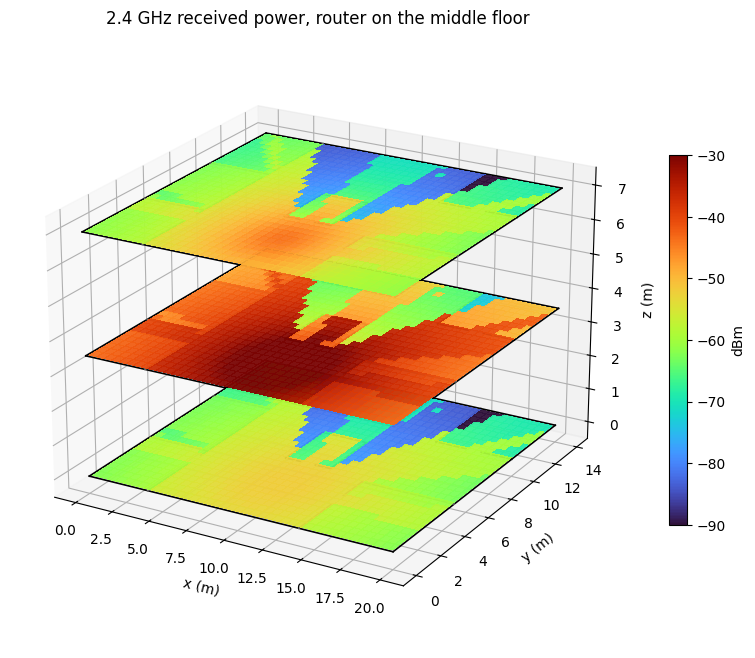

In [3]:
pts, fl, xs, ys = building_grid(W, H, 3, res=0.25)
P = received_power_3d(ROUTER, pts, fl, walls, 2.4e9)
fig = plt.figure(figsize=(11, 8)); ax = fig.add_subplot(projection="3d")
Xg, Yg = np.meshgrid(xs, ys); cmap = plt.cm.turbo; norm = plt.Normalize(-90, -30)
for k in range(3):
    img = P[fl == k].reshape(ys.size, xs.size)
    ax.plot_surface(Xg, Yg, np.full_like(Xg, k*FLOOR_HEIGHT), facecolors=cmap(norm(img)), rstride=2, cstride=2,
                    shade=False, linewidth=0, antialiased=False, alpha=0.95)
    for (a, b, m) in walls:
        ax.plot([a[0], b[0]], [a[1], b[1]], [k*FLOOR_HEIGHT]*2, color="k" if m in ("concrete", "brick") else "0.4", lw=1.2)
ax.scatter(*ROUTER, color="w", edgecolor="k", s=120, marker="*", depthshade=False)
ax.set(xlabel="x (m)", ylabel="y (m)", zlabel="z (m)", title="2.4 GHz received power, router on the middle floor")
ax.view_init(elev=22, azim=-60)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.6, label="dBm"); plt.show()

# 3. Statistics

In [4]:
rows = []
for f in (2.4e9, 5e9):
    for r in floor_statistics(received_power_3d(ROUTER, pts, fl, walls, f), fl):
        rows.append({"band (GHz)": f/1e9, **r})
stats = pd.DataFrame(rows).round(2)
stats

,band (GHz),floor,coverage %,median dBm,p10 dBm,mean dBm
0,2.4,0,73.79,-60.02,-81.23,-62.86
1,2.4,1,99.17,-40.82,-61.83,-42.75
2,2.4,2,76.18,-58.91,-79.95,-61.00
3,5.0,0,11.70,-74.22,-110.60,-79.78
4,5.0,1,84.69,-47.91,-84.20,-52.67
5,5.0,2,24.60,-73.02,-109.33,-77.93


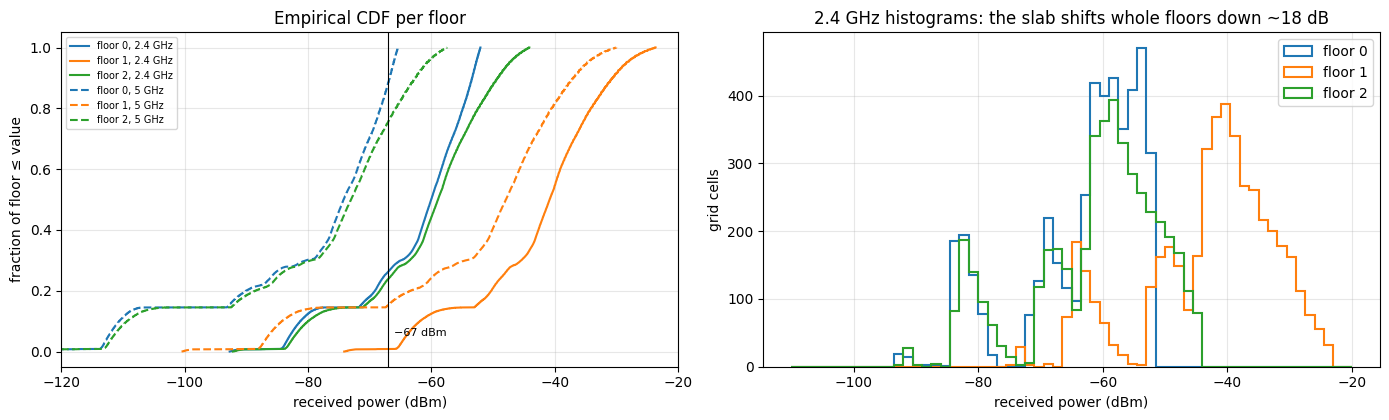

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for f, ls in ((2.4e9, "-"), (5e9, "--")):
    Pf = received_power_3d(ROUTER, pts, fl, walls, f)
    for k, col in zip(range(3), ("C0", "C1", "C2")):
        v, F = empirical_cdf(Pf[fl == k]); axes[0].plot(v, F, col, ls=ls, label=f"floor {k}, {f/1e9:g} GHz")
axes[0].axvline(-67, color="k", lw=0.8); axes[0].text(-66, 0.05, "−67 dBm", fontsize=8)
axes[0].set(xlabel="received power (dBm)", ylabel="fraction of floor ≤ value", title="Empirical CDF per floor", xlim=(-120, -20))
axes[0].legend(fontsize=7); axes[0].grid(alpha=0.3)
for k, col in zip(range(3), ("C0", "C1", "C2")):
    axes[1].hist(P[fl == k], bins=60, range=(-110, -20), histtype="step", color=col, lw=1.5, label=f"floor {k}")
axes[1].set(xlabel="received power (dBm)", ylabel="grid cells", title="2.4 GHz histograms: the slab shifts whole floors down ~18 dB")
axes[1].legend(); axes[1].grid(alpha=0.3); plt.tight_layout(); plt.show()

**Reading the statistics.**
- The router's own floor gets about 99% coverage at 2.4 GHz. One slab costs the neighboring
  floors roughly 18 dB, which drops them to about 75%.
- At **5 GHz** the other floors collapse to about 12–25%: a higher slab loss on top of the
  higher free-space loss. Multi-storey buildings need an access point per floor for 5 GHz.
- The **10th percentile** (p10) answers "how bad are the worst desks?". It's often more useful
  than the mean, which hides dead zones.

# 4. Animation: the router walks the hallway

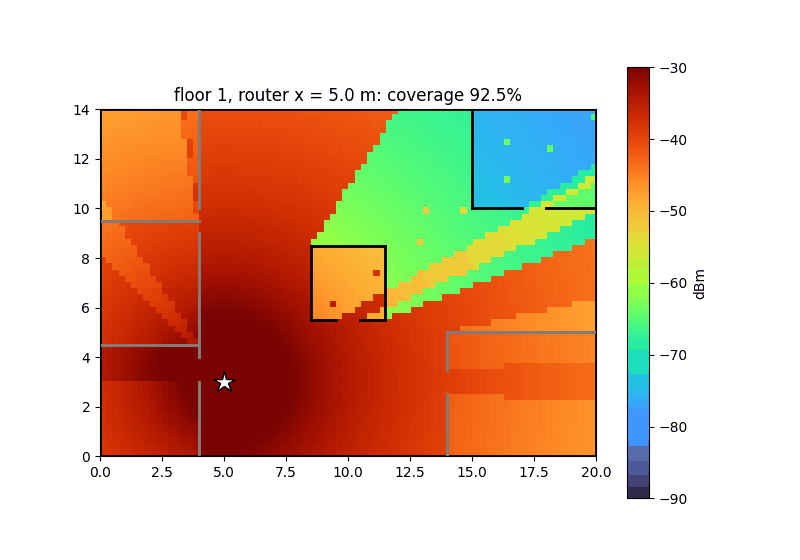

coverage along the walk (%): [92.5 93.  93.7 94.7 95.9 97.1 97.6 97.6 96.9 95.8 95.4 95.9 97.3 98.6
 99.3 98.7 97.4 96.7 96.6 96.8 97.3 97.3 96.7 95.8]
best spot on the walk: x = 10.2 m (99.3%)


In [6]:
path = hallway_path(24, floor=1)
sel = fl == 1
fig, ax = plt.subplots(figsize=(8, 5.6))
img0 = received_power_3d(path[0], pts[sel], fl[sel], walls, 2.4e9).reshape(ys.size, xs.size)
im = ax.imshow(img0, origin="lower", extent=[0, W, 0, H], cmap="turbo", vmin=-90, vmax=-30)
for (a, b, m) in walls:
    ax.plot([a[0], b[0]], [a[1], b[1]], color="k" if m in ("concrete", "brick") else "0.5", lw=2)
star, = ax.plot([], [], "w*", ms=16, mec="k"); title = ax.set_title("")
fig.colorbar(im, ax=ax, label="dBm")
# coverage series computed once, outside the animation (FuncAnimation may call a frame twice)
cov = [100*np.mean(received_power_3d(r, pts[sel], fl[sel], walls, 2.4e9) >= -67) for r in path]
def frame(i):
    v = received_power_3d(path[i], pts[sel], fl[sel], walls, 2.4e9)
    im.set_data(v.reshape(ys.size, xs.size)); star.set_data([path[i, 0]], [path[i, 1]])
    title.set_text(f"floor 1, router x = {path[i,0]:.1f} m: coverage {cov[i]:.1f}%")
    return im, star, title
ani = animation.FuncAnimation(fig, frame, frames=len(path), blit=False)
gif = pathlib.Path("wifi_building3d_hallway.gif")
ani.save(gif, writer=animation.PillowWriter(fps=6)); plt.close(fig)
display(Image(filename=str(gif)))
print("coverage along the walk (%):", np.round(cov, 1))
print(f"best spot on the walk: x = {path[int(np.argmax(cov)), 0]:.1f} m ({max(cov):.1f}%)")

# 5. The MATLAB twin

[`learn/matlab/wifi_building3d.m`](../learn/matlab/wifi_building3d.m) reads the **same walls file**
exported from Python (one source of truth), builds the same N×M crossing matrix with implicit
expansion, prints per-floor statistics, and writes its own animated GIF with `imwrite`. The cell
runs MATLAB headless if it's installed:

router (10.0, 3.0, 6.0) m at 2.4 GHz
floor 0: coverage  73.79 %   median  -60.02 dBm   p10  -81.23 dBm
floor 1: coverage  99.17 %   median  -40.82 dBm   p10  -61.84 dBm
floor 2: coverage  76.18 %   median  -58.91 dBm   p10  -79.96 dBm
wrote D:/Summer2026/Dispersion-Assisted-GS-Phase-Recovery/notebooks/wifi_building3d_hallway_matlab.gif (24 frames)

Python, same router:
floor 0: coverage  73.79 %   median  -60.02 dBm   p10  -81.23 dBm
floor 1: coverage  99.17 %   median  -40.82 dBm   p10  -61.83 dBm
floor 2: coverage  76.18 %   median  -58.91 dBm   p10  -79.95 dBm


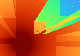

In [7]:
matlab = shutil.which("matlab") or r"C:\Program Files\MATLAB\R2025b\bin\matlab.exe"
if pathlib.Path(matlab).exists():
    tmp = pathlib.Path(tempfile.mkdtemp()); csv = export_walls_csv(tmp / "walls.csv", walls)
    mgif = pathlib.Path("wifi_building3d_hallway_matlab.gif").resolve()
    cmd = f"addpath('learn/matlab'); wifi_building3d('{csv.as_posix()}', [10 3 6], 2.4, '{mgif.as_posix()}')"
    out = subprocess.run([matlab, "-batch", cmd], cwd=pathlib.Path.cwd().parent, capture_output=True, text=True, timeout=900).stdout
    print("\n".join(l for l in out.splitlines() if l.startswith(("floor", "router", "wrote"))))
    print("\nPython, same router:")
    for r in floor_statistics(P, fl):
        print(f"floor {r['floor']}: coverage {r['coverage %']:6.2f} %   median {r['median dBm']:7.2f} dBm   p10 {r['p10 dBm']:7.2f} dBm")
    display(Image(filename=str(mgif)))
else:
    print("MATLAB not found — skipped")

Coverage and medians agree to every printed digit. The **10th percentiles differ in the last
digit** because MATLAB's `prctile` and NumPy's `percentile` use different interpolation rules
between samples. That's a definition difference, not a bug, and the kind of thing worth
checking whenever two tools "should" agree.

## Exercises
1. Put one router on each floor and report the building-wide coverage (use the max over routers).
2. Make the stairwell core leak: give it a vertical "shaft" with no slab loss. Which floors improve?
3. Time the vectorized function at `res=0.1`. How does run time scale with the number of points?
4. Animate the router moving *vertically* through the floors instead, and plot coverage vs. height.